# IMPORT

In [641]:
%load_ext autoreload
%autoreload 2

from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt
import torch
from torch.utils.data import (
    DataLoader,
    random_split,
)
from dataset import TransferDatasetToDevice, GPUDataLoader
from models import VAE, ConditionalVAE, GAN, ConditionalGAN, DDPM

from gan import (
    gan_train_step,
    gan_validation_step,
    make_gan_optimizers,
    gan_grl_train_step,
    conditional_gan_train_step,
    conditional_gan_validation_step
)

from configs import TrainConfig
from experiment import Experiment, run
from vae import (
    vae_train_step, vae_validation_step,
    conditional_vae_train_step, conditional_vae_validation_step,
)
from ddpm import ddpm_train_step, ddpm_validation_step
from plots import plot_history, plot_image_grid, make_image_callback

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# DATA LOAD AND PREPROCESSING

MNIST contains grayscale images of handwritten digits. Pixel values are converted to the range [0, 1]. The training data is split into training and validation subsets; the original test set is used for final evaluation.

The split uses a fixed random seed. 

download

In [526]:
full_train_dataset = MNIST(
    root='data',
    train=True,
    download=True,
    transform=ToTensor(),
)

test_dataset = MNIST(
    root='data',
    train=False,
    download=True,
    transform=ToTensor(),
)

example of data and information about dataset

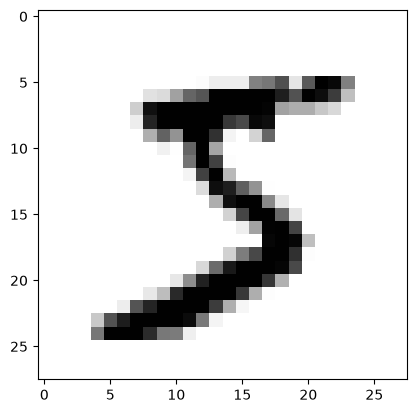

In [527]:
image, label = full_train_dataset[0]

plt.imshow(image.squeeze(dim=0), label=label, cmap='gray_r')
plt.show()

In [528]:
print("Количество примеров:", len(full_train_dataset))
print("Форма изображения:", image.shape)
print("Тип данных:", image.dtype)
print("Диапазон:", image.min().item(), image.max().item())
print("Метка:", label)

Количество примеров: 60000
Форма изображения: torch.Size([1, 28, 28])
Тип данных: torch.float32
Диапазон: 0.0 1.0
Метка: 5


split train_dataset into train and validation

In [529]:
train_dataset, valid_dataset = random_split(
    dataset=full_train_dataset,
    lengths=[50000, 10000],
    generator=torch.Generator().manual_seed(21)
)

make dataloaders

In [530]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_dataset = TransferDatasetToDevice(dataset=train_dataset, device=device)
valid_dataset = TransferDatasetToDevice(dataset=valid_dataset, device=device)
test_dataset = TransferDatasetToDevice(dataset=test_dataset, device=device)

loader_class = GPUDataLoader if device.type == "cuda" else DataLoader

batch_size = 500

for dataset in (train_dataset, valid_dataset, test_dataset):
    if len(dataset) % batch_size != 0:
        raise ValueError(
            f"Dataset size ({len(dataset)}) must be divisible "
            f"by batch_size ({batch_size})"
        )

train_loader = loader_class(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
)

valid_loader = loader_class(
    valid_dataset,
    batch_size=batch_size,
    shuffle=False,
)

test_loader = loader_class(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
)

# MODELS

The models share the same experiment interface. Training and validation are implemented as separate step functions. Validation does not update model parameters.

For VAE and DDPM, the model with the lowest validation loss is restored after training. GAN experiments keep the final model because a lower adversarial loss does not necessarily mean better generated images.

## Generative Model of the Variational AutoEncoder

The encoder predicts the mean and log variance of a Gaussian latent distribution. A latent vector is sampled with the reparameterization trick and passed to the decoder.

In [531]:
number_of_images = 3
latent_dim = 2
fixed_z = torch.randn(number_of_images, latent_dim, device=device)

def generate_vae_preview(model):
    return torch.sigmoid(model.decode(fixed_z))

vae_callback = make_image_callback(
    generate_fn=generate_vae_preview,
    every=50,
)

experiment = Experiment(
    name="vae_mnist_v1",
    model_class=VAE,
    device=device,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
    train_step_fn=vae_train_step,
    validation_step_fn=vae_validation_step,
    model_params={
        "latent_dim": latent_dim,
        "hidden_dims": [512, 512, 512],
    },
    epoch_callback=vae_callback,
)


train_config = TrainConfig(
    epochs=300,
    patience=5,
    lr=2e-5,
    weight_decay=1e-4,
)


Experiment: vae_mnist_v1


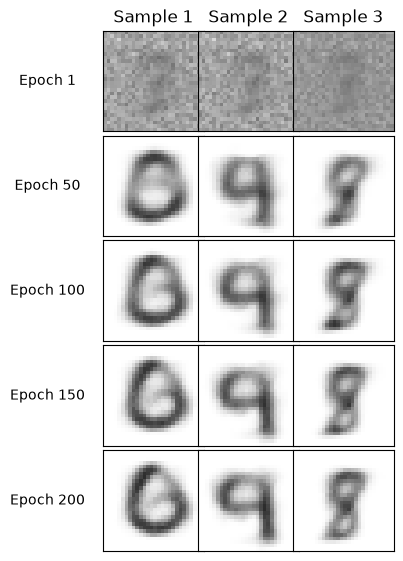

Completed epochs: 229 | Total training time: 63.35 s
Best epoch: 224 | Best validation loss: 150.7157

Test metrics:
  loss: 151.1639
  reconstruction: 145.0314
  kl: 6.1325


In [532]:
result = run(
    experiment=experiment,
    config=train_config,
    verbose=1,
)

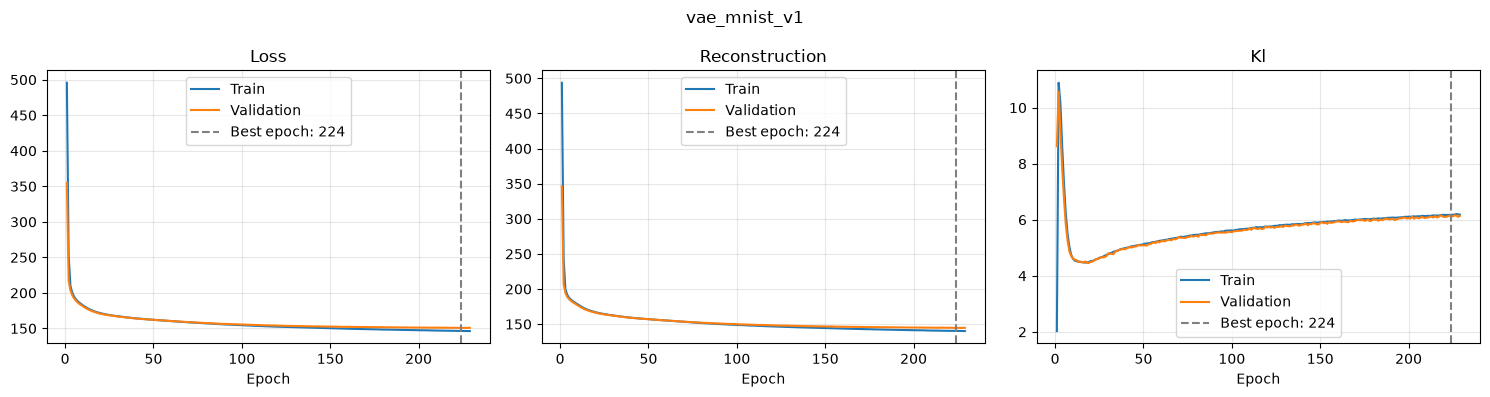

In [533]:
plot_history(
    history=result["history"],
    best_epoch=result["best_epoch"],
    name=result["name"],
)

### The distribution of the latent vectors

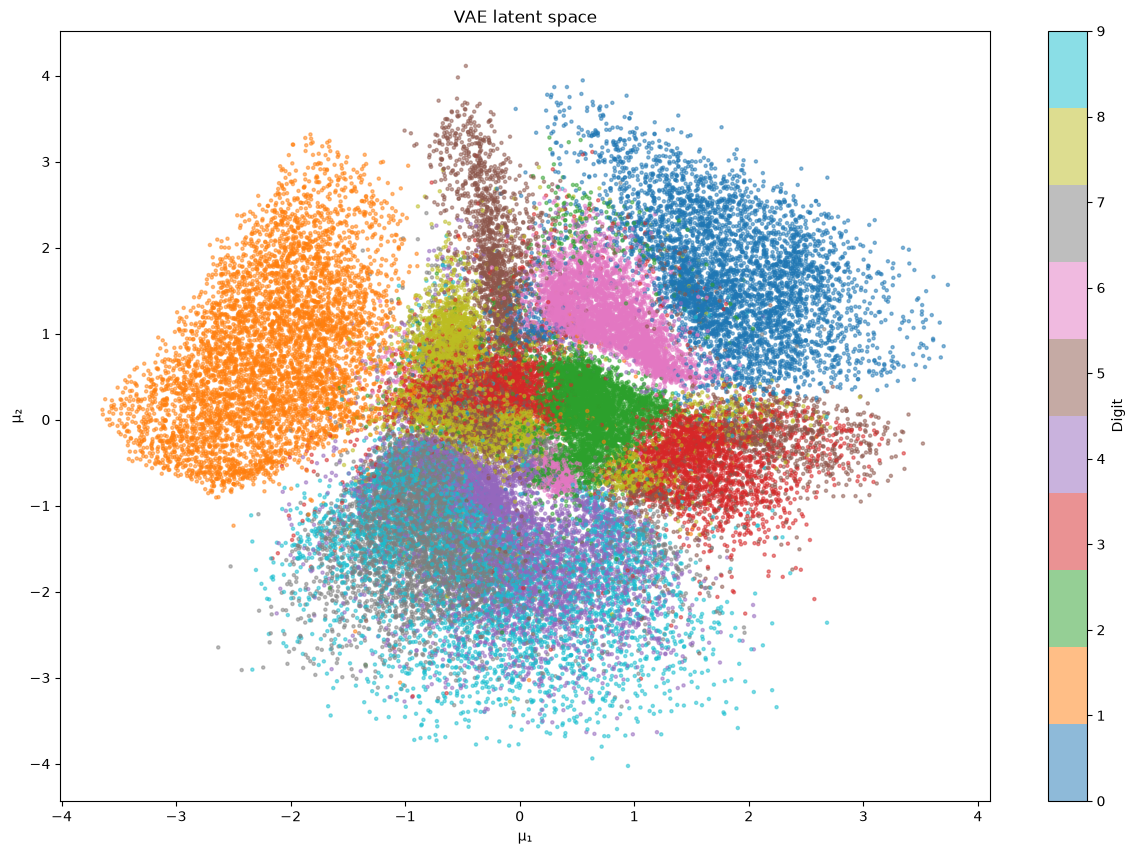

In [534]:
vae_model = result['model']
vae_model.eval()

mu_all = []
labels_all = []

with torch.no_grad():
    for images, labels in train_loader:
        mu, _ = vae_model.encode(images.to(device))

        mu_all.append(mu.cpu())
        labels_all.append(labels.cpu())

mu_all = torch.cat(mu_all).numpy()
labels_all = torch.cat(labels_all).numpy()

plt.figure(figsize=(15,10))
points = plt.scatter(
    mu_all[:, 0], mu_all[:, 1],
    c=labels_all,
    cmap='tab10',
    s=5,
    alpha=0.5,
)

plt.colorbar(points, ticks=range(10), label="Digit")
plt.xlabel("μ₁")
plt.ylabel("μ₂")
plt.title("VAE latent space")
plt.show()

Plot the digits from decoder

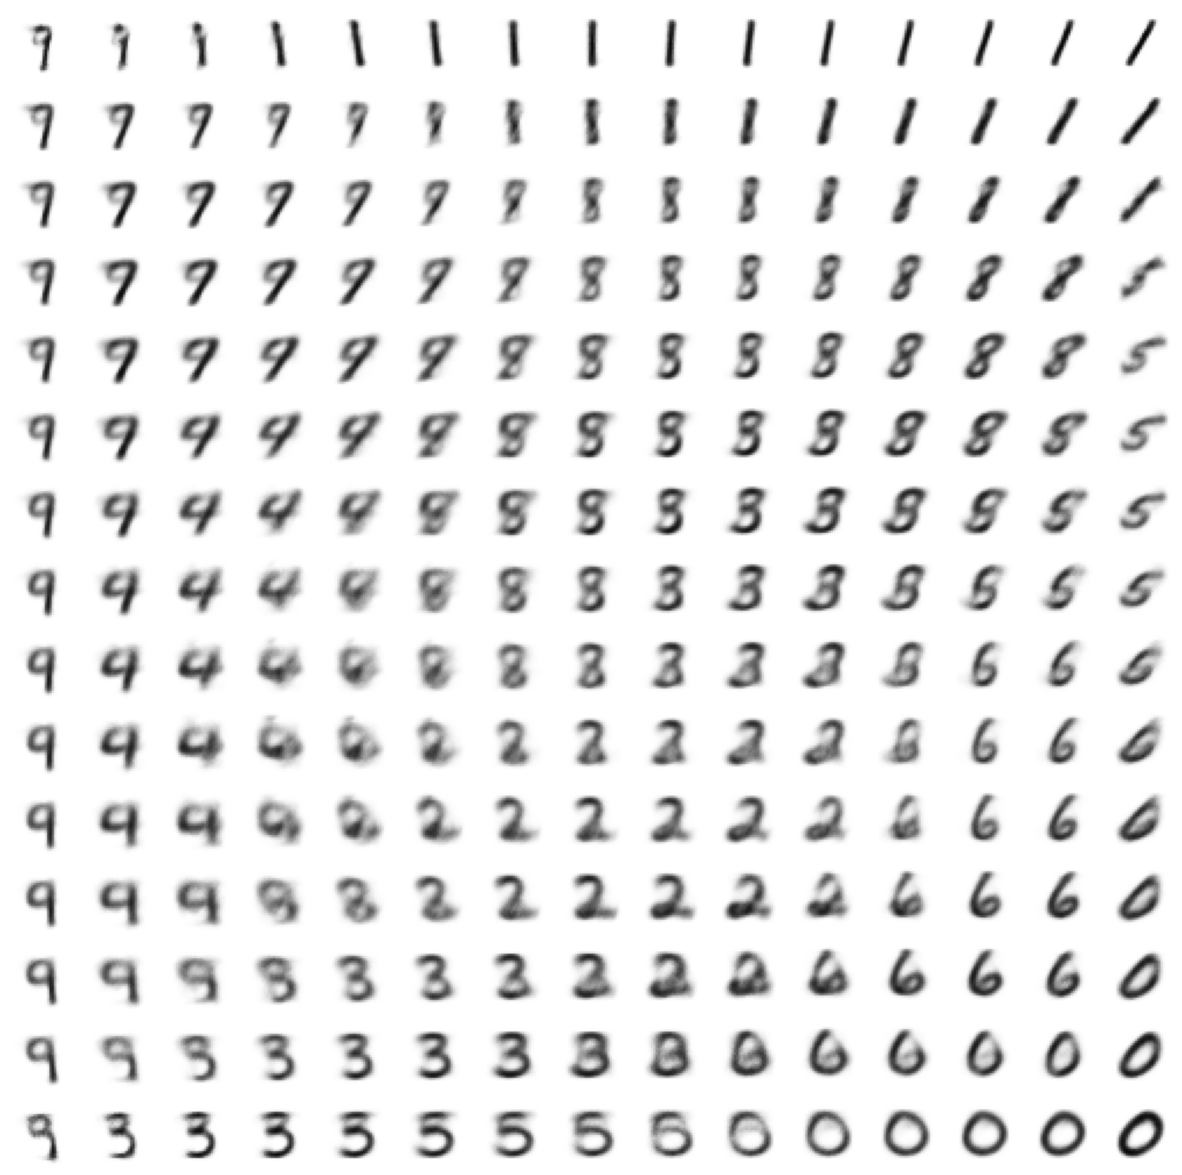

In [535]:
nrows = 15
ncols = 15

normal = torch.distributions.Normal(0.0, 1.0)

z1 = normal.icdf(torch.linspace(0.01, 0.99, nrows, device=device))
z2 = normal.icdf(torch.linspace(0.01, 0.99, ncols, device=device))

z = torch.cartesian_prod(z1, z2)

vae_model = result["model"]
vae_model.eval()

with torch.no_grad():
    logits = vae_model.decode(z)
    images = torch.sigmoid(logits)

plot_image_grid(images=images, nrows=nrows, ncols=ncols)

The latent plot contains regions associated with different digits, but these regions overlap. The model learns useful structure without receiving class labels during training.

Nearby latent points often produce similar images, and moving across the grid gives gradual changes in shape. Some transitions produce ambiguous digits. The images are also soft, showing the limits of this small latent representation and the reconstruction model.

### Check VAE with 10 degree latent space 

This additional experiment gives the VAE more latent capacity. The hidden layer sizes and regularization also change, so it compares complete model configurations rather than latent dimensions alone.

The image grid below uses independent random latent vectors. It is a sample gallery, not a map of the full latent space.

In [538]:
fixed_z_10 = torch.randn(number_of_images, 10, device=device)

def generate_vae_preview(model):
    return torch.sigmoid(model.decode(fixed_z_10))

vae_callback_10 = make_image_callback(
    generate_fn=generate_vae_preview,
    every=50,
)

experiment_10d = Experiment(
    name="vae_mnist_10_latent",
    model_class=VAE,
    device=device,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
    train_step_fn=vae_train_step,
    validation_step_fn=vae_validation_step,
    model_params={
        "latent_dim": 10,
        "hidden_dims" : [512, 1024, 512]
    },
    epoch_callback=vae_callback_10
)

train_config = TrainConfig(
    epochs=300,
    patience=5,
    lr=2e-5,
    weight_decay=1e-5,
)


Experiment: vae_mnist_10_latent


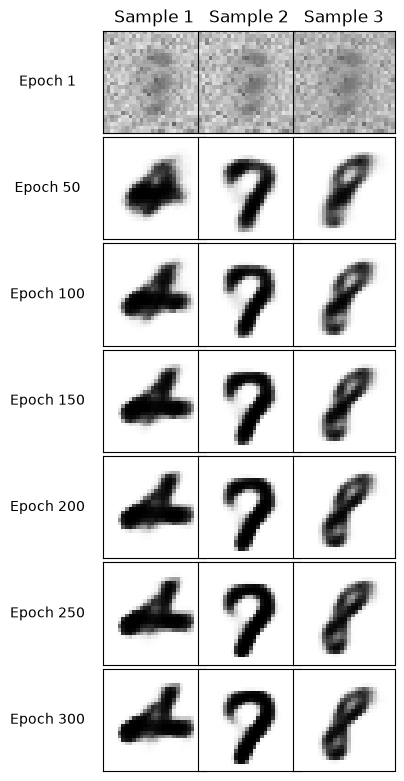

Completed epochs: 300 | Total training time: 85.75 s
Best epoch: 300 | Best validation loss: 106.1535

Test metrics:
  loss: 105.2816
  reconstruction: 86.8506
  kl: 18.4309


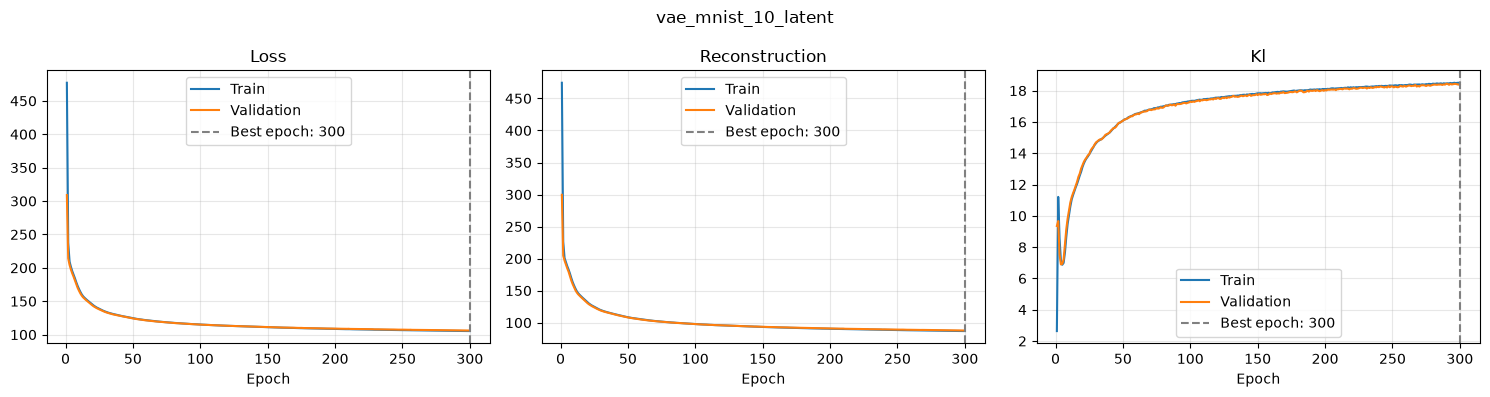

In [539]:
result_10d = run(
    experiment=experiment_10d,
    config=train_config,
    verbose=1,
)

plot_history(
    history=result_10d["history"],
    best_epoch=result_10d["best_epoch"],
    name=result_10d["name"],
)

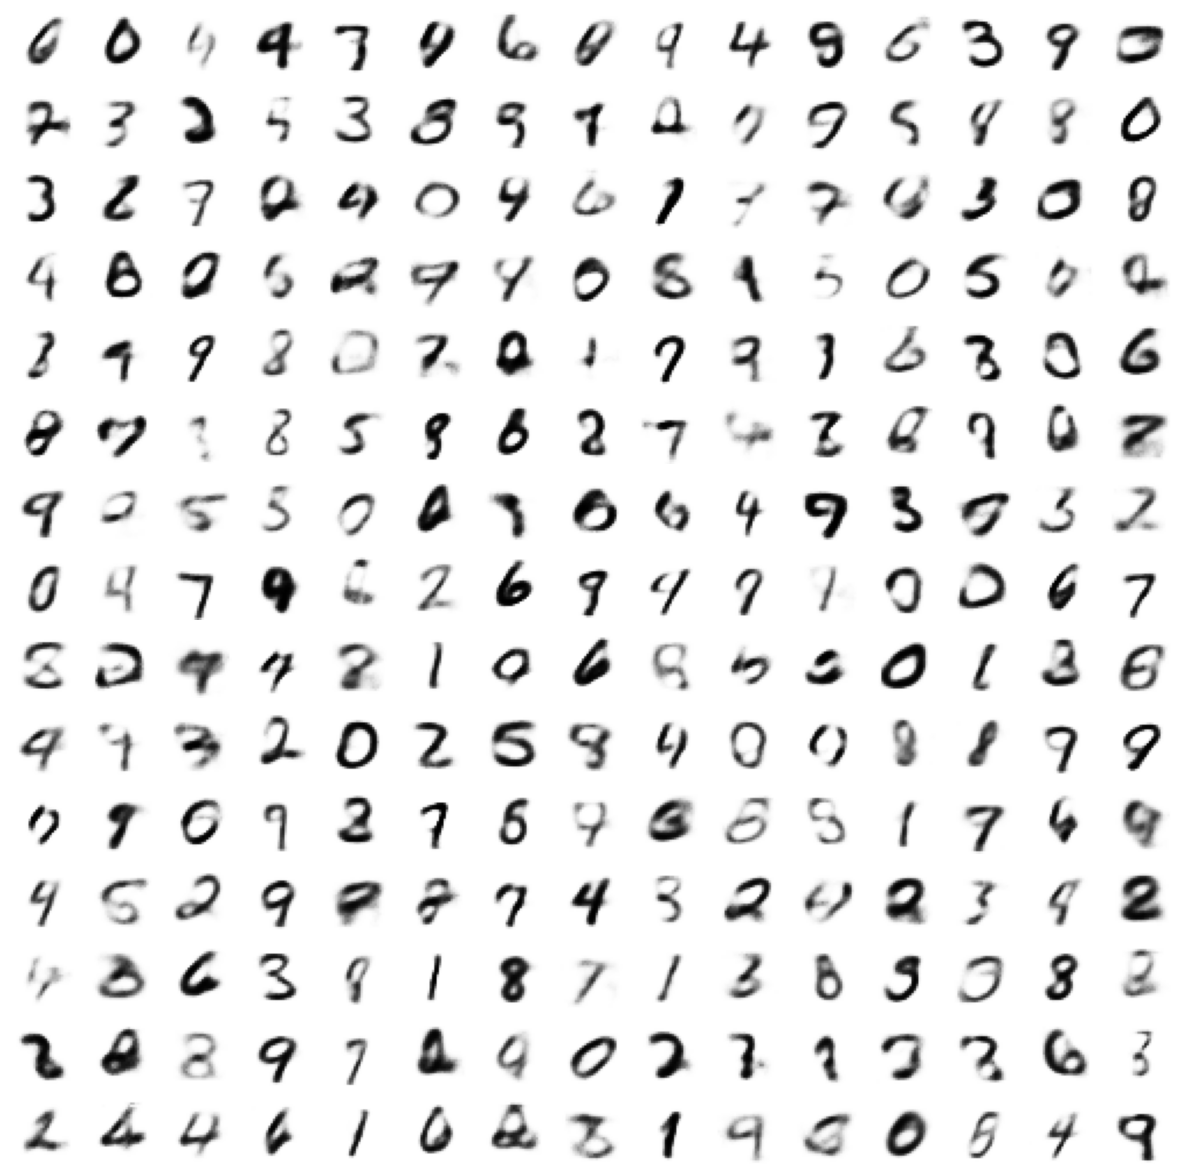

In [540]:
nrows = 15
ncols = 15

vae_model = result_10d["model"]
vae_model.eval()

z = torch.randn(nrows * ncols, 10, device=device)

with torch.no_grad():
    logits = vae_model.decode(z)
    images = torch.sigmoid(logits)

plot_image_grid(images=images, nrows=nrows, ncols=ncols)

## Supervised Generative Model of VAE

The conditional VAE receives a digit label in addition to a latent vector. In this implementation, the encoder still receives only the image. The decoder receives the latent vector concatenated with a one-hot label.

The label tells the decoder which digit to generate. The latent vector can represent variations in writing style. The training loss still combines reconstruction and KL terms.

In [541]:
number_of_images = 3
latent_dim = 1

fixed_z_1 = torch.randn(number_of_images, latent_dim, device=device)
fixed_labels = torch.tensor([0, 1, 2], device=device)

def generate_cond_vae_preview(model):
    return torch.sigmoid(model.decode(fixed_z_1, fixed_labels))

vae_callback_1 = make_image_callback(
    generate_fn=generate_cond_vae_preview,
    every=50,
)

experiment_cond_vae = Experiment(
    name="cond_vae_mnist_v1",
    model_class=ConditionalVAE,
    device=device,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
    train_step_fn=conditional_vae_train_step,
    validation_step_fn=conditional_vae_validation_step,
    model_params={
        "latent_dim": 1,
        "num_classes" : 10,
        "hidden_dims" : [512, 512, 512]
    },
    epoch_callback=vae_callback_1,
)

train_config = TrainConfig(
    epochs=300,
    patience=5,
    lr=2e-5,
    weight_decay=1e-4,
)


Experiment: cond_vae_mnist_v1


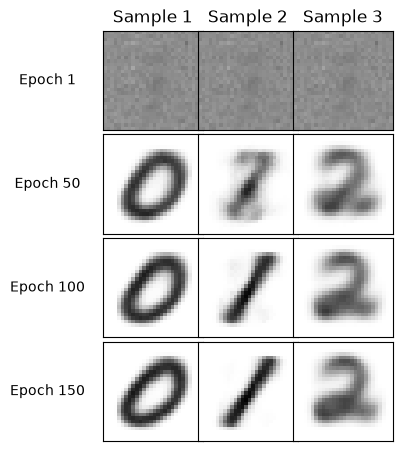

Completed epochs: 185 | Total training time: 52.62 s
Best epoch: 180 | Best validation loss: 147.9970

Test metrics:
  loss: 148.4743
  reconstruction: 145.6362
  kl: 2.8381


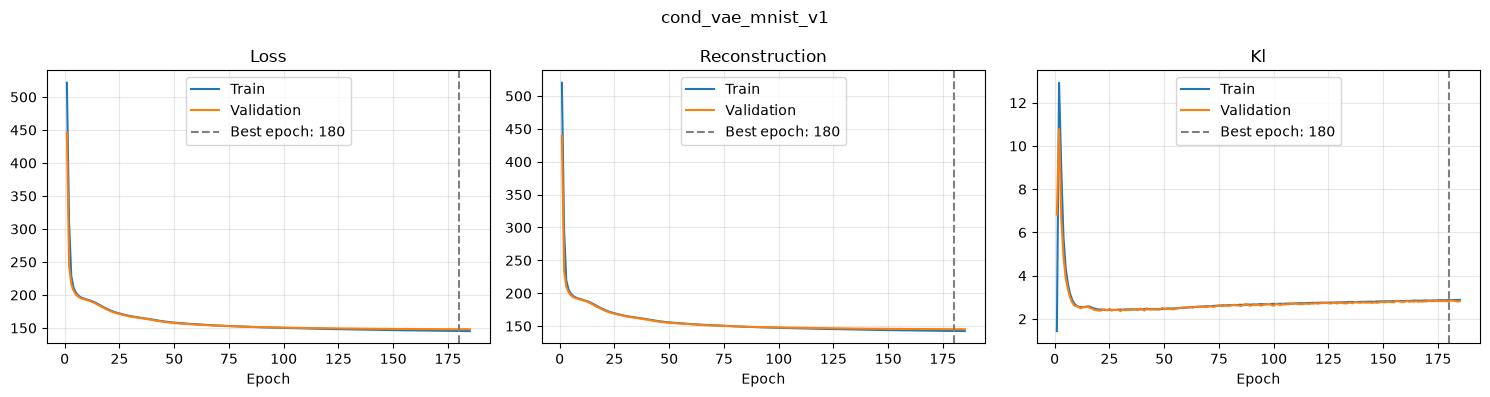

In [542]:
result_cond_vae = run(
    experiment=experiment_cond_vae,
    config=train_config,
    verbose=1,
)

plot_history(
    history=result_cond_vae["history"],
    best_epoch=result_cond_vae["best_epoch"],
    name=result_cond_vae["name"],
)

Create a mesh of 15 points in latent space. Combine them with 10 digit labels and plot 15x10 reconstructed digits.

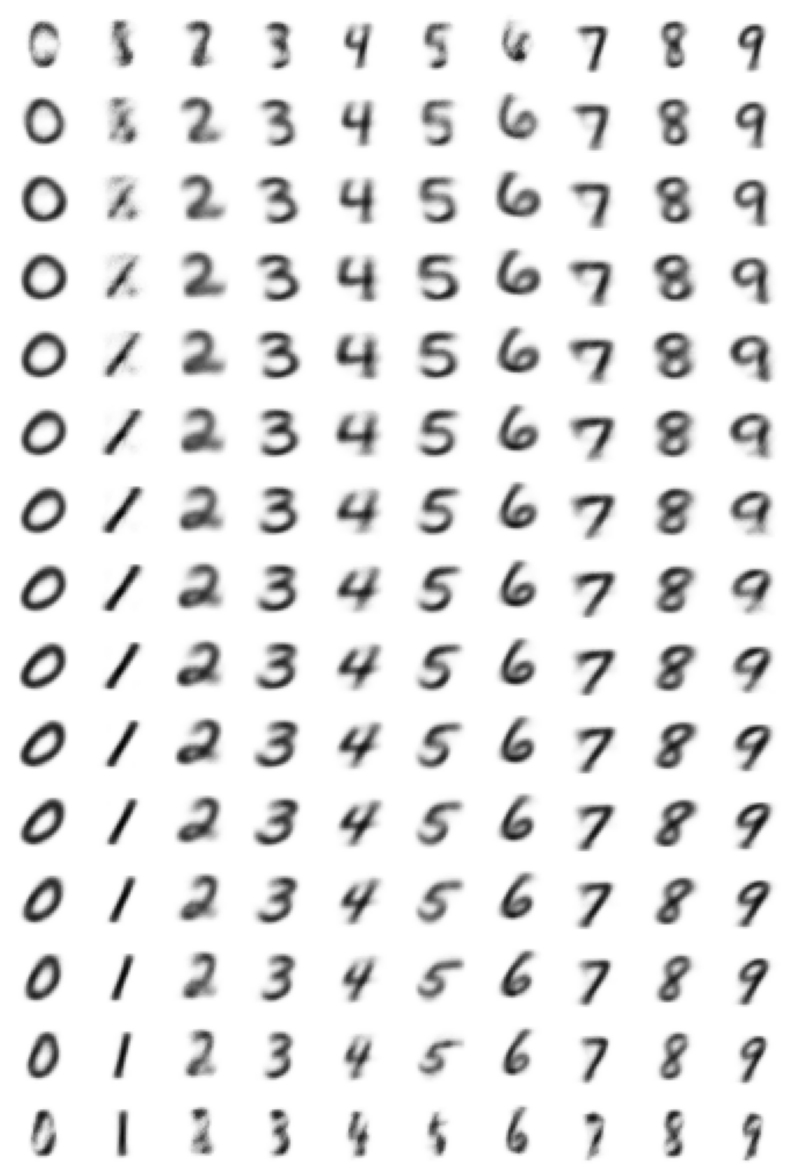

In [543]:
nrows = 15
ncols = 10

normal = torch.distributions.Normal(0.0, 1.0)

z = normal.icdf(torch.linspace(0.01, 0.99, nrows, device=device))
z = z.repeat_interleave(ncols).unsqueeze(1)

labels = torch.arange(ncols, device=device).repeat(nrows)

cond_vae_model = result_cond_vae["model"]
cond_vae_model.eval()

with torch.no_grad():
    logits = cond_vae_model.decode(z, labels)
    images = torch.sigmoid(logits)

plot_image_grid(images=images, nrows=nrows, ncols=ncols)

Most columns show the requested digit, so conditioning gives direct control over the generated class. Changes in the latent value affect stroke shape and writing style, although these changes can be small.

Some samples remain blurred or ambiguous. Supplying a label helps select the class, but it does not remove all limitations of the decoder or latent representation.

## GAN

The generator maps a random latent vector to an image. The discriminator predicts a logit for whether an image is real or generated.

The generator uses fixed Fourier features of the latent vector together with the original coordinates. These features provide additional input functions without increasing the number of independent latent coordinates.

Training alternates between a discriminator update and a generator update.


Experiment: gan_mnist_v1


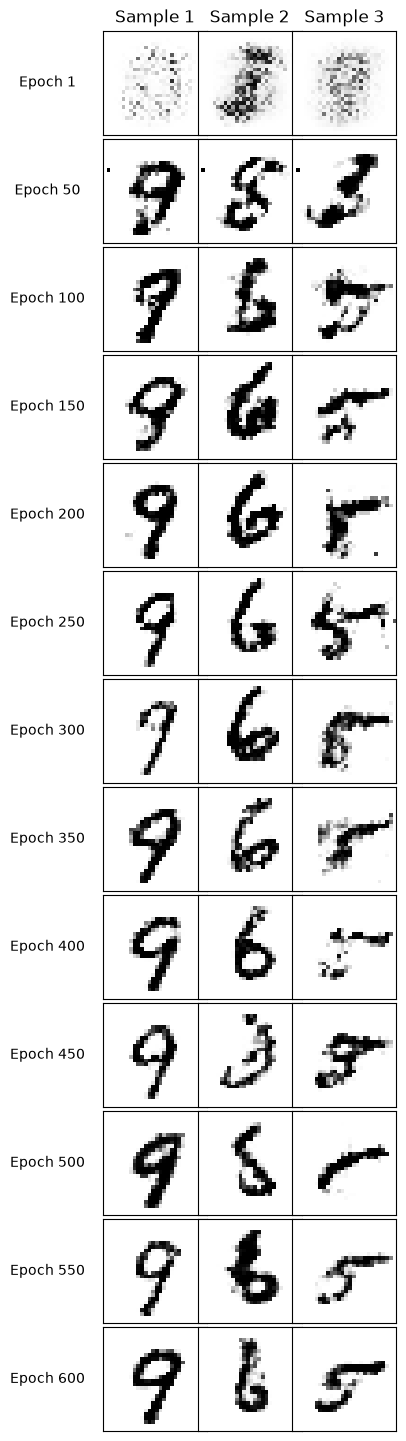

Completed epochs: 600 | Total training time: 226.41 s

Test metrics:
  generator_loss: 0.8994
  discriminator_loss: 0.6372
  real_score: 0.5844
  fake_score: 0.4400


In [663]:
number_of_images = 3
latent_dim = 2
fixed_z = torch.randn(number_of_images, latent_dim, device=device)

def generate_gan_preview(model) -> torch.Tensor:
    return model.generate(fixed_z)


gan_callback = make_image_callback(
    generate_fn=generate_gan_preview,
    every=50,
)

experiment_gan = Experiment(
    name="gan_mnist_v1",
    model_class=GAN,
    device=device,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
    train_step_fn=gan_train_step,
    validation_step_fn=gan_validation_step,
    model_params={
        "generator_hidden_dims": [512, 512, 512],
        "discriminator_hidden_dims": [256, 256],
        "latent_dim": latent_dim,
        "image_shape": (1, 28, 28),
        "n_freqs": 64,
        "fourier_scale": 2.0,
    },
    optimizer_factory=make_gan_optimizers,
    monitor=None,
    epoch_callback=gan_callback,
)

gan_config = TrainConfig(
    epochs=600,
    patience=None,
    lr=5e-4,
    weight_decay=0.0,
)

result_gan = run(
    experiment=experiment_gan,
    config=gan_config,
    verbose=1,
)

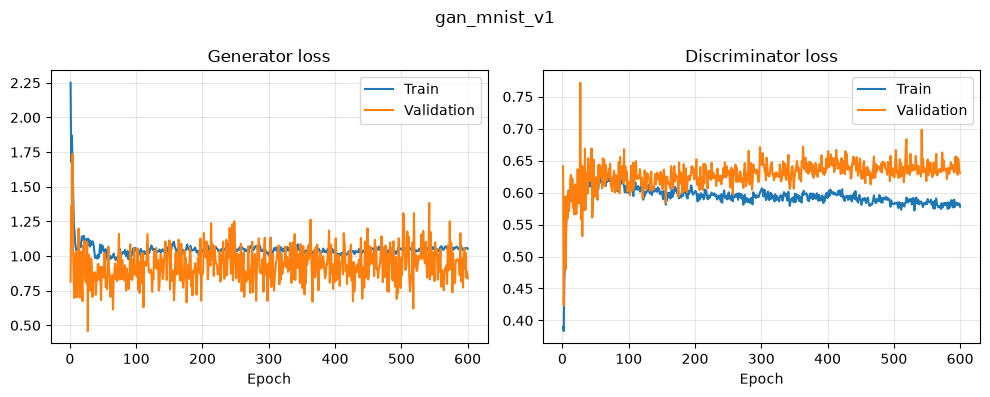

In [590]:
plot_history(
    history=result_gan["history"],
    best_epoch=result_gan["best_epoch"],
    name=result_gan["name"],
)

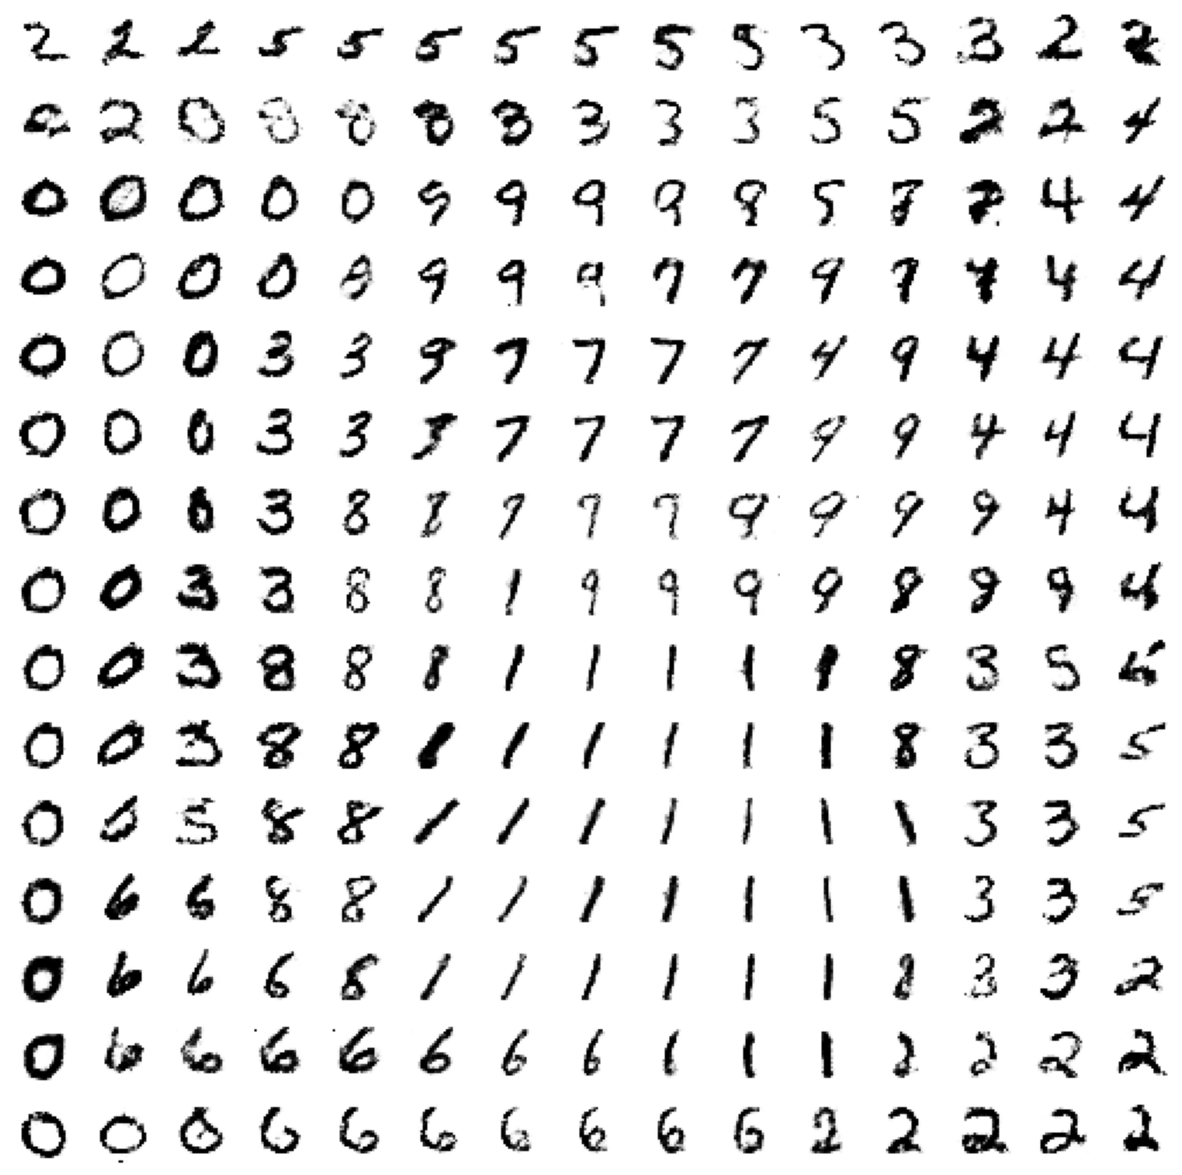

In [591]:
nrows = 15
ncols = 15

normal = torch.distributions.Normal(0.0, 1.0)

z1 = normal.icdf(torch.linspace(0.01, 0.99, nrows, device=device))
z2 = normal.icdf(torch.linspace(0.01, 0.99, ncols, device=device))

z = torch.cartesian_prod(z1, z2)

gan_model = result_gan["model"]
gan_model.eval()

with torch.no_grad():
    images = gan_model.generate(z)

plot_image_grid(images=images, nrows=nrows, ncols=ncols)

The generator produces recognizable digits and gradual changes across parts of the latent grid. Some regions contain similar samples, and some images have incomplete strokes or unclear shapes.

The discriminator remains able to distinguish real and generated data, but the results do not show a permanent winner in the adversarial game. A decrease in discriminator loss alone would not prove that image quality is improving.

Generated images change during training without a steady improvement at every checkpoint. Longer training therefore does not guarantee better samples.

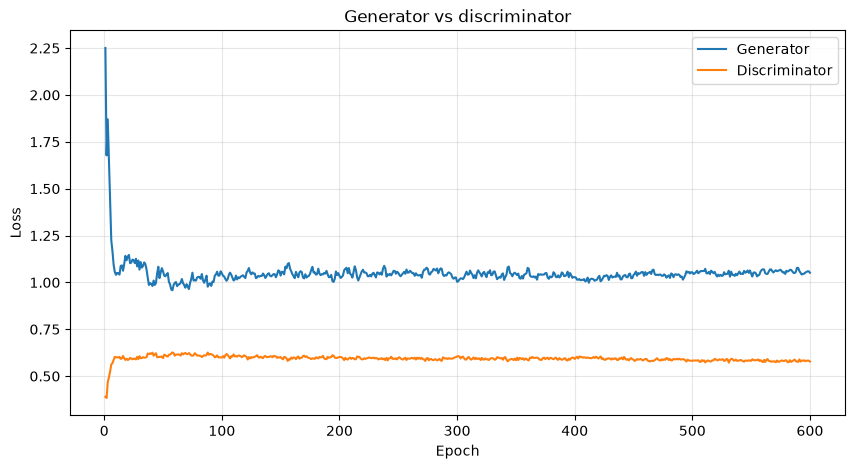

In [592]:
history = result_gan["history"]

plt.figure(figsize=(10, 5))

plt.plot(
    history["epoch"],
    history["train_generator_loss"],
    label="Generator",
)
plt.plot(
    history["epoch"],
    history["train_discriminator_loss"],
    label="Discriminator",
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator vs discriminator")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## GAN WITH GRL

Gradient reversal keeps an image unchanged during the forward pass and reverses its gradient during the backward pass. The discriminator therefore learns to detect generated images, while the generator receives a signal in the opposite direction.


Experiment: gan_mnist_grl


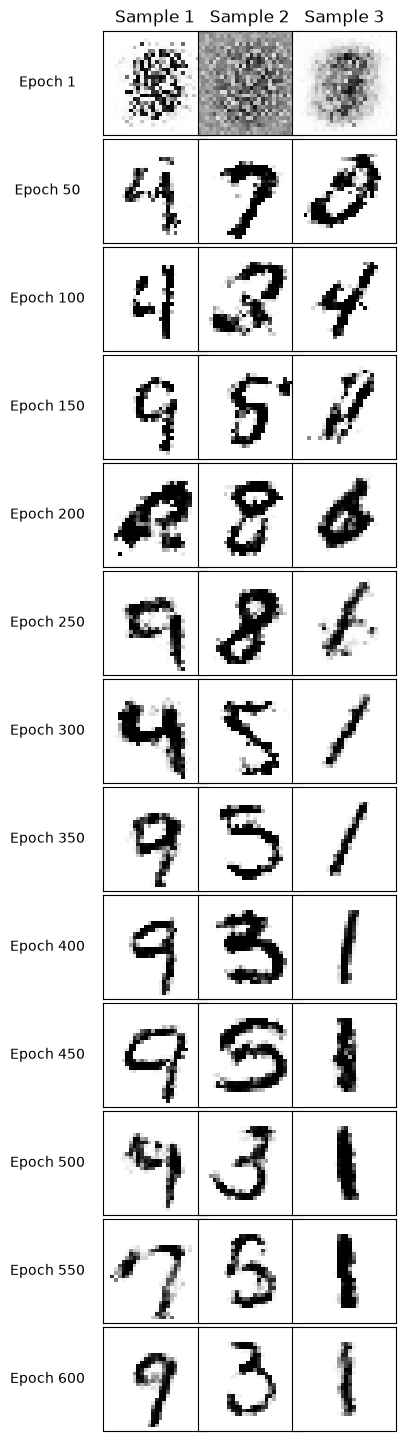

Completed epochs: 600 | Total training time: 187.72 s

Test metrics:
  generator_loss: 1.1610
  discriminator_loss: 0.6057
  real_score: 0.6112
  fake_score: 0.3940


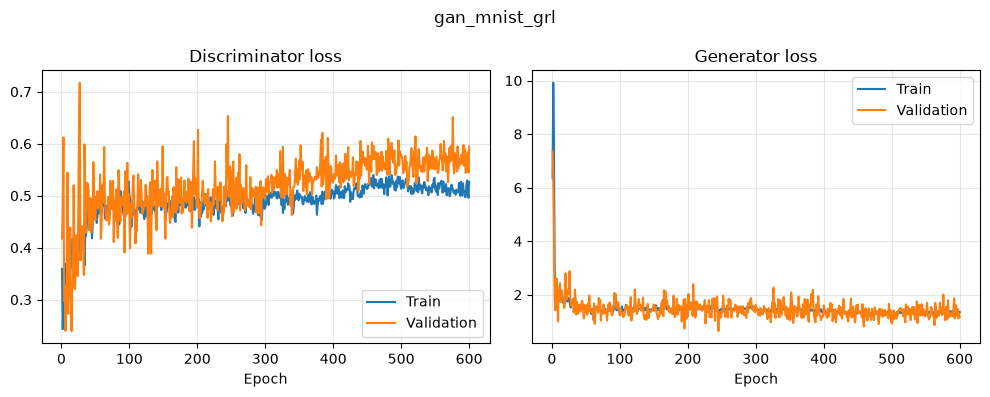

In [594]:
number_of_images = 3
latent_dim = 2
fixed_z = torch.randn(number_of_images, latent_dim, device=device)

def generate_gan_preview(model) -> torch.Tensor:
    return model.generate(fixed_z)


gan_callback = make_image_callback(
    generate_fn=generate_gan_preview,
    every=50,
)

experiment_gan_grl = Experiment(
    name="gan_mnist_grl",
    model_class=GAN,
    device=device,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
    train_step_fn=gan_grl_train_step,
    validation_step_fn=gan_validation_step,
    model_params={
        "generator_hidden_dims": [512, 512, 512],
        "discriminator_hidden_dims": [256, 256],
        "latent_dim": latent_dim,
        "image_shape": (1, 28, 28),
        "n_freqs": 64,
        "fourier_scale": 2.0,
    },
    optimizer_factory=make_gan_optimizers,
    monitor=None,
    epoch_callback=gan_callback,
)

gan_config = TrainConfig(
    epochs=600,
    patience=None,
    lr=5e-4,
    weight_decay=0.0,
)

result_gan_grl = run(
    experiment=experiment_gan_grl,
    config=gan_config,
    verbose=1,
)

plot_history(
    history=result_gan_grl["history"],
    best_epoch=result_gan_grl["best_epoch"],
    name=result_gan_grl["name"],
)

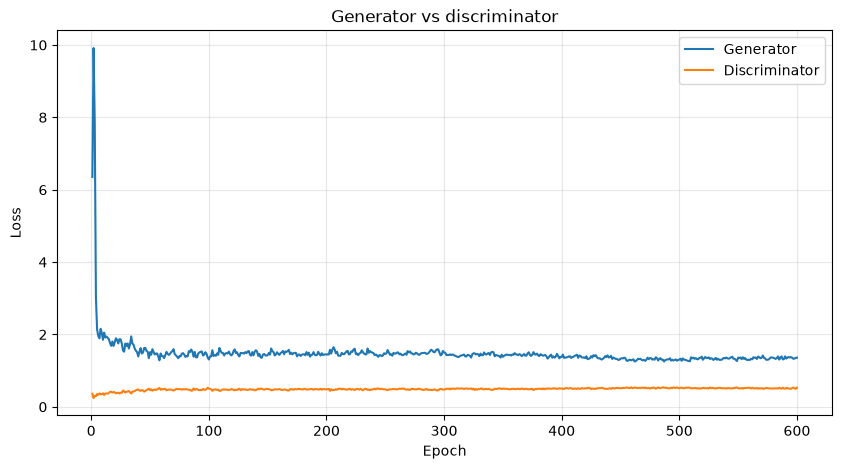

In [664]:
history = result_gan_grl["history"]

plt.figure(figsize=(10, 5))

plt.plot(
    history["epoch"],
    history["train_generator_loss"],
    label="Generator",
)
plt.plot(
    history["epoch"],
    history["train_discriminator_loss"],
    label="Discriminator",
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Generator vs discriminator")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

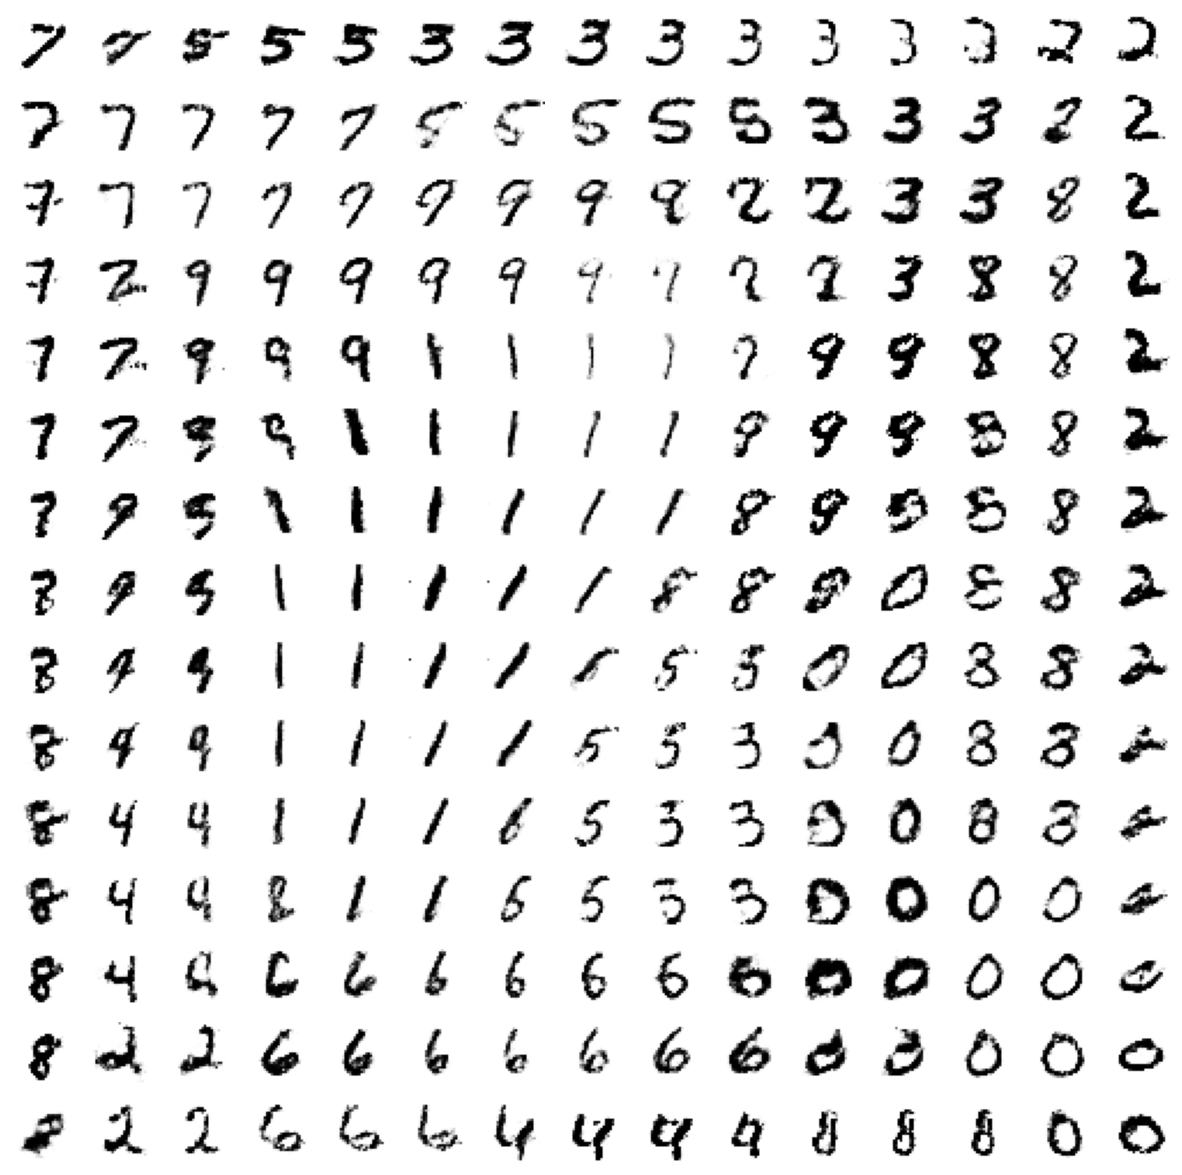

In [665]:
nrows = 15
ncols = 15

normal = torch.distributions.Normal(0.0, 1.0)

z1 = normal.icdf(torch.linspace(0.01, 0.99, nrows, device=device))
z2 = normal.icdf(torch.linspace(0.01, 0.99, ncols, device=device))

z = torch.cartesian_prod(z1, z2)

gan_grl_model = result_gan_grl["model"]
gan_grl_model.eval()

with torch.no_grad():
    images = gan_grl_model.generate(z)

plot_image_grid(images=images, nrows=nrows, ncols=ncols)

The GRL model also generates recognizable digits, but repeated shapes and imperfect strokes remain. Its visual quality is broadly comparable to the standard GAN in these examples; the samples do not establish that either method is consistently better.

## Conditional GAN

The generator receives a latent representation concatenated with a one-hot digit label. The discriminator receives a flattened image concatenated with its label. It learns whether the image-label pair matches the real data distribution.

The networks use the same alternating training procedure as the standard GAN. The discriminator still returns a single real-or-generated logit, not a separate class prediction.


Experiment: conditional_gan_mnist


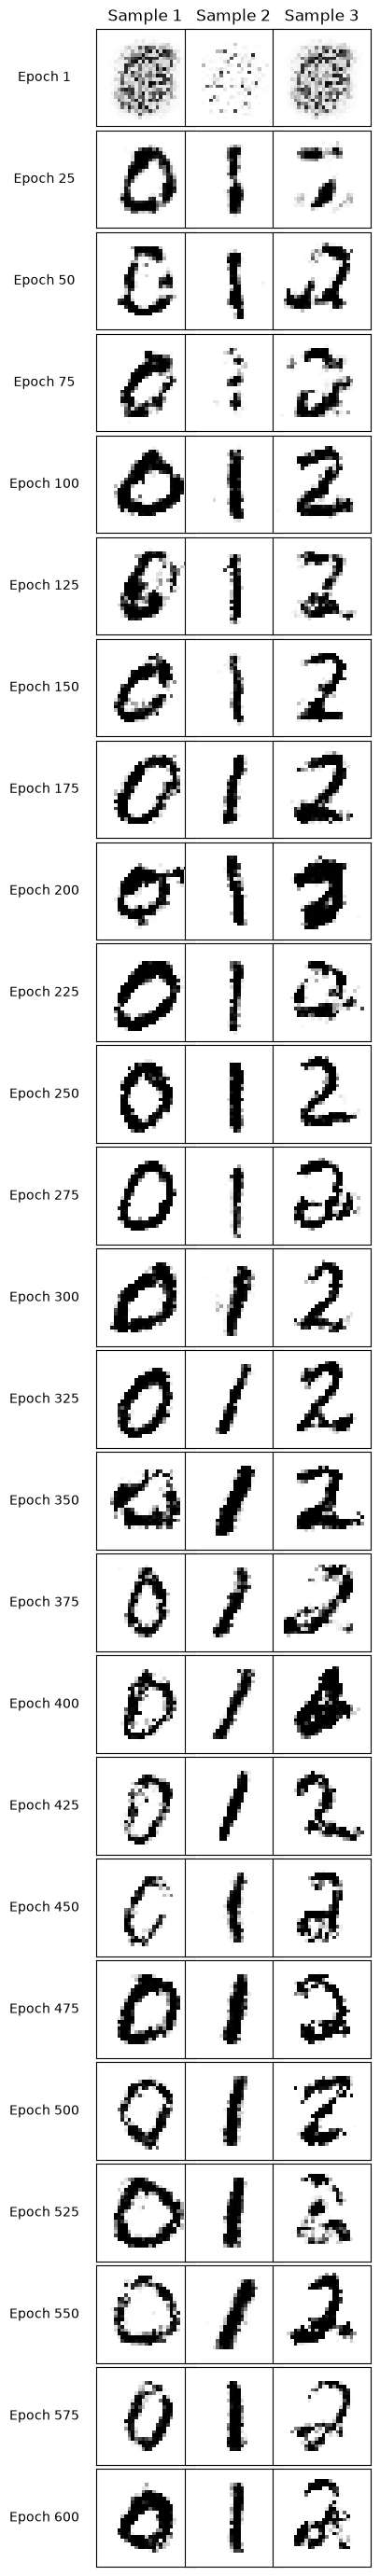

Completed epochs: 600 | Total training time: 272.78 s

Test metrics:
  generator_loss: 1.0812
  discriminator_loss: 0.5888
  real_score: 0.6032
  fake_score: 0.3779


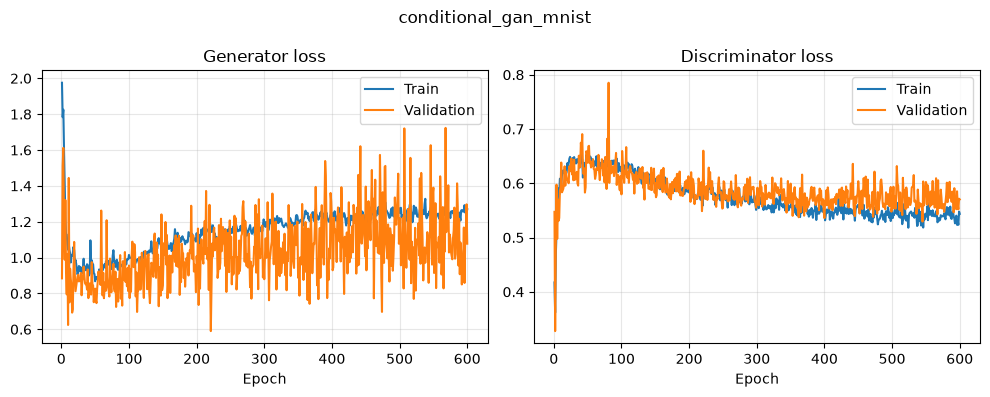

In [ ]:
number_of_images = 3
latent_dim = 1

fixed_z_cond_gan = torch.randn(number_of_images, latent_dim, device=device)
fixed_labels = torch.tensor([0, 1, 2], device=device)

def generate_gan_preview(model) -> torch.Tensor:
    return model.generate(fixed_z_cond_gan, fixed_labels)


gan_callback = make_image_callback(
    generate_fn=generate_gan_preview,
    every=50,
)

experiment_cond_gan = Experiment(
    name="conditional_gan_mnist",
    model_class=ConditionalGAN,
    device=device,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
    train_step_fn=conditional_gan_train_step,
    validation_step_fn=conditional_gan_validation_step,
    model_params={
        "generator_hidden_dims": [512, 512, 512],
        "discriminator_hidden_dims": [256, 256],
        "latent_dim": latent_dim,
        "image_shape": (1, 28, 28),
        "n_freqs": 64,
        "fourier_scale": 2.0,
    },
    optimizer_factory=make_gan_optimizers,
    monitor=None,
    epoch_callback=gan_callback,
)

gan_config = TrainConfig(
    epochs=600,
    patience=None,
    lr=5e-4,
    weight_decay=0.0,
)

result_cond_gan = run(
    experiment=experiment_cond_gan,
    config=gan_config,
    verbose=1,
)

plot_history(
    history=result_cond_gan["history"],
    best_epoch=result_cond_gan["best_epoch"],
    name=result_cond_gan["name"],
)

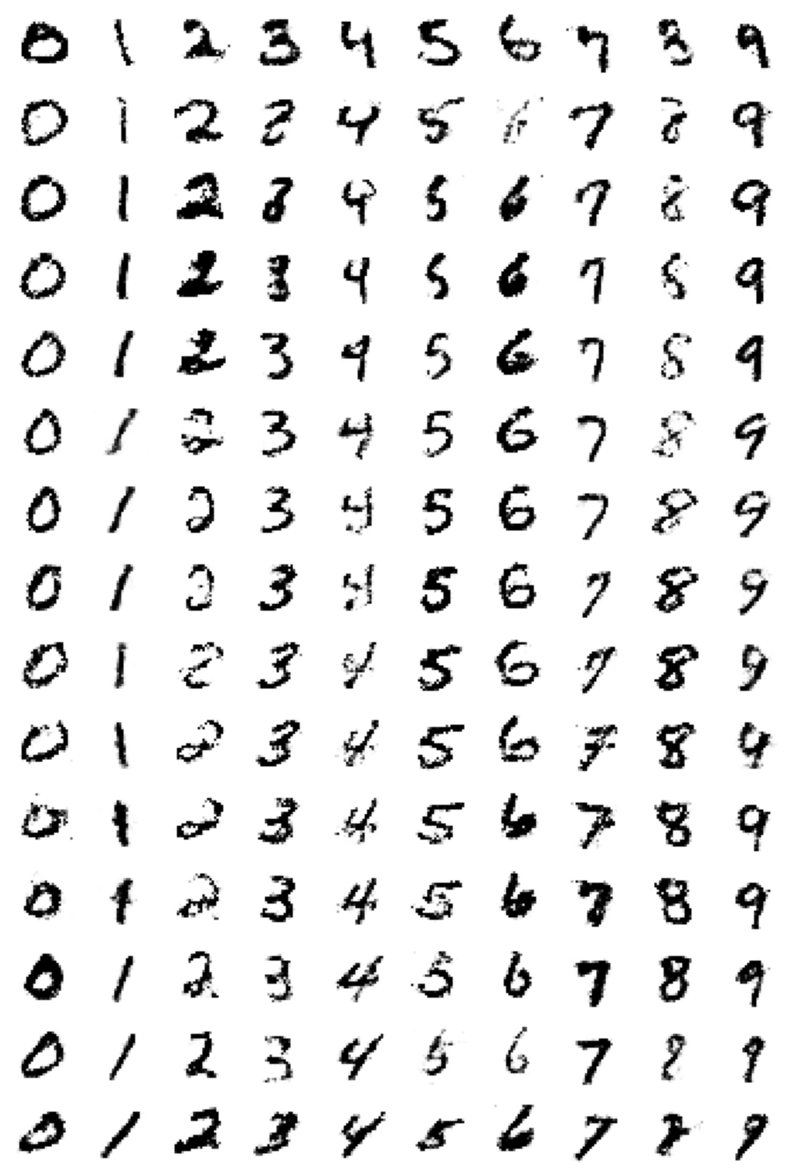

In [600]:
nrows = 15
ncols = 10

normal = torch.distributions.Normal(0.0, 1.0)

z = normal.icdf(torch.linspace(0.01, 0.99, nrows, device=device))
z = z.repeat_interleave(ncols).unsqueeze(1)

labels = torch.arange(ncols, device=device).repeat(nrows)

cond_gan_model = result_cond_gan["model"]
cond_gan_model.eval()

with torch.no_grad():
    images = cond_gan_model.generate(z, labels)

plot_image_grid(images=images, nrows=nrows, ncols=ncols)

The generated columns mostly follow their requested labels. Changing the latent value changes the appearance of a digit while preserving its class in many samples.

Some images contain broken or distorted strokes. Conditioning makes class selection easier, but it does not guarantee complete or realistic digit shapes.

## DDPM - Denoising Diffusion Probabilistic Model

A DDPM learns to generate images by reversing a gradual noising process. During training, a clean image is mixed with Gaussian noise at a randomly selected timestep. The network predicts the noise that was added.

The examples below use the same original image with independent Gaussian noise at different timesteps. They show how the signal becomes harder to recognize. 

Values are clipped only for display. A noisy image can naturally leave the display range because Gaussian noise is unbounded.

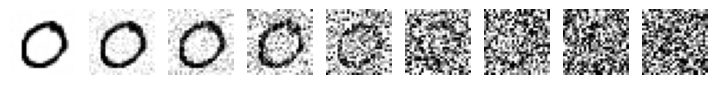

In [636]:
ddpm_model = DDPM(num_steps=1000).to(device)

images, _ = next(iter(train_loader))

timesteps = torch.tensor([0, 50, 100, 200, 300, 500, 600, 800, 999], device=device)

images = images[:1] * 2 - 1
images = images.repeat(len(timesteps), 1, 1, 1)

noise = torch.randn_like(images)

noisy_images = ddpm_model.add_noise(images, timesteps, noise)

display_images = ((noisy_images + 1) / 2).clamp(0, 1)
plot_image_grid(images=display_images, nrows=1, ncols=len(timesteps))


Experiment: ddpm_mnist


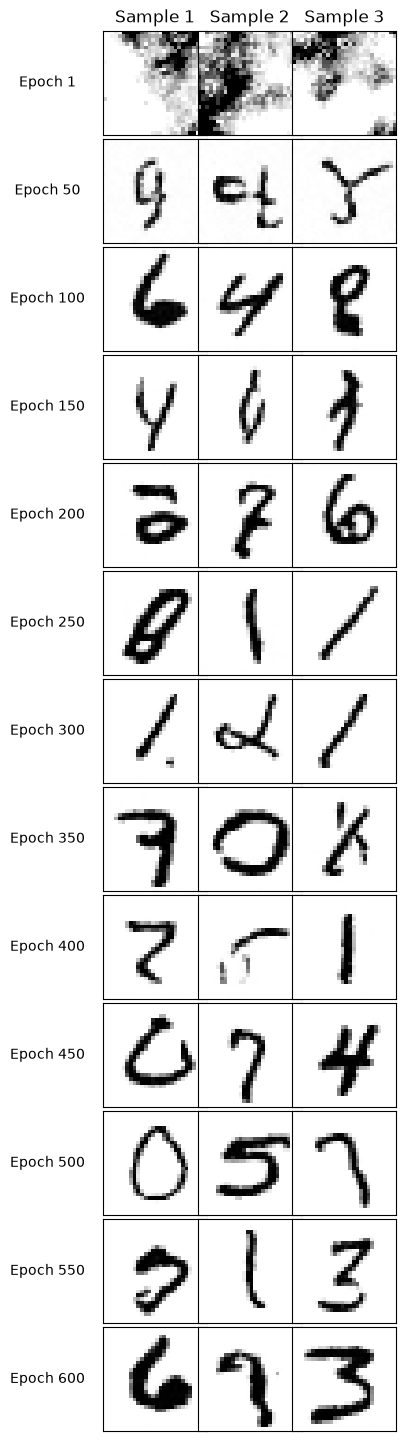

Completed epochs: 600 | Total training time: 1542.93 s
Best epoch: 574 | Best validation loss: 0.0217

Test metrics:
  loss: 0.0227


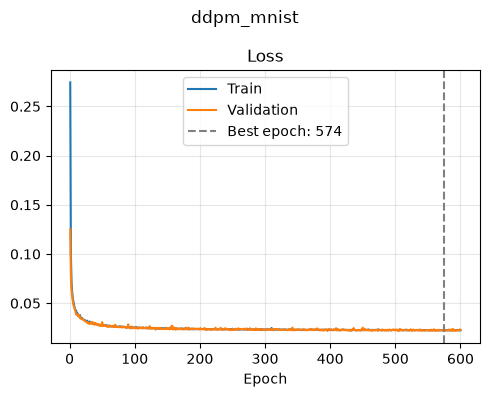

In [656]:
fixed_noise_ddpm = torch.randn(3, 1, 28, 28, device=device)

def generate_ddpm_preview(model) -> torch.Tensor:
    return model.generate(fixed_noise_ddpm)

ddpm_callback = make_image_callback(
    generate_fn=generate_ddpm_preview,
    every=50,
)

experiment_ddpm = Experiment(
    name="ddpm_mnist",
    model_class=DDPM,
    device=device,
    train_loader=train_loader,
    valid_loader=valid_loader,
    test_loader=test_loader,
    train_step_fn=ddpm_train_step,
    validation_step_fn=ddpm_validation_step,
    model_params={
        "image_shape": (1, 28, 28),
        "hidden_dims": [32, 64, 64],
        "num_steps": 1000,
        "beta_start": 1e-4,
        "beta_end": 0.02,
    },
    monitor="loss",
    epoch_callback=ddpm_callback,
)

ddpm_config = TrainConfig(
    epochs=600,
    patience=None,
    lr=1e-3,
    weight_decay=0.0,
)

result_ddpm = run(
    experiment=experiment_ddpm,
    config=ddpm_config,
    verbose=1,
)

plot_history(
    history=result_ddpm["history"],
    best_epoch=result_ddpm["best_epoch"],
    name=result_ddpm["name"],
)

Each image starts from an independent standard Gaussian noise tensor. The model repeatedly predicts noise and applies a reverse diffusion update. Random noise is added at intermediate reverse steps, but not at the final step.

The final tensors are mapped back to [0, 1] and clipped for display. This grid is a gallery of generated samples.

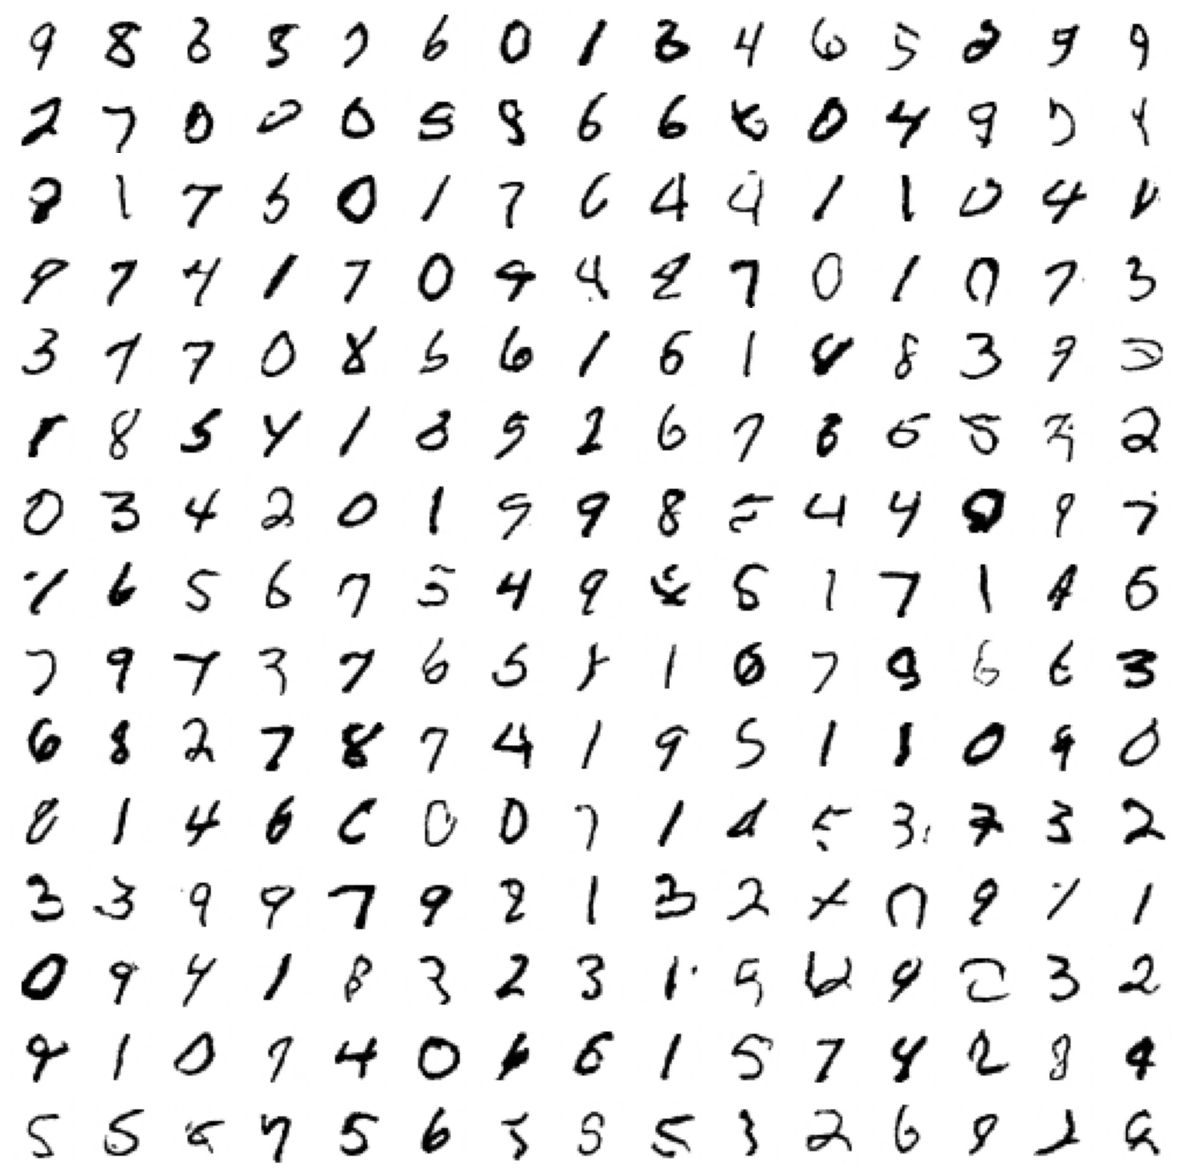

In [657]:
ddpm_model = result_ddpm["model"]
ddpm_model.eval()

noise = torch.randn(225, 1, 28, 28, device=device)
images = ddpm_model.generate(noise)

plot_image_grid(images=images, nrows=15, ncols=15)

#### From Noise to a Digit

This grid records selected states from a single sampling run. Read it from left to right and then from top to bottom. The first image is the initial noise, and the last image is the final generated sample.

The labels show the remaining diffusion timestep.

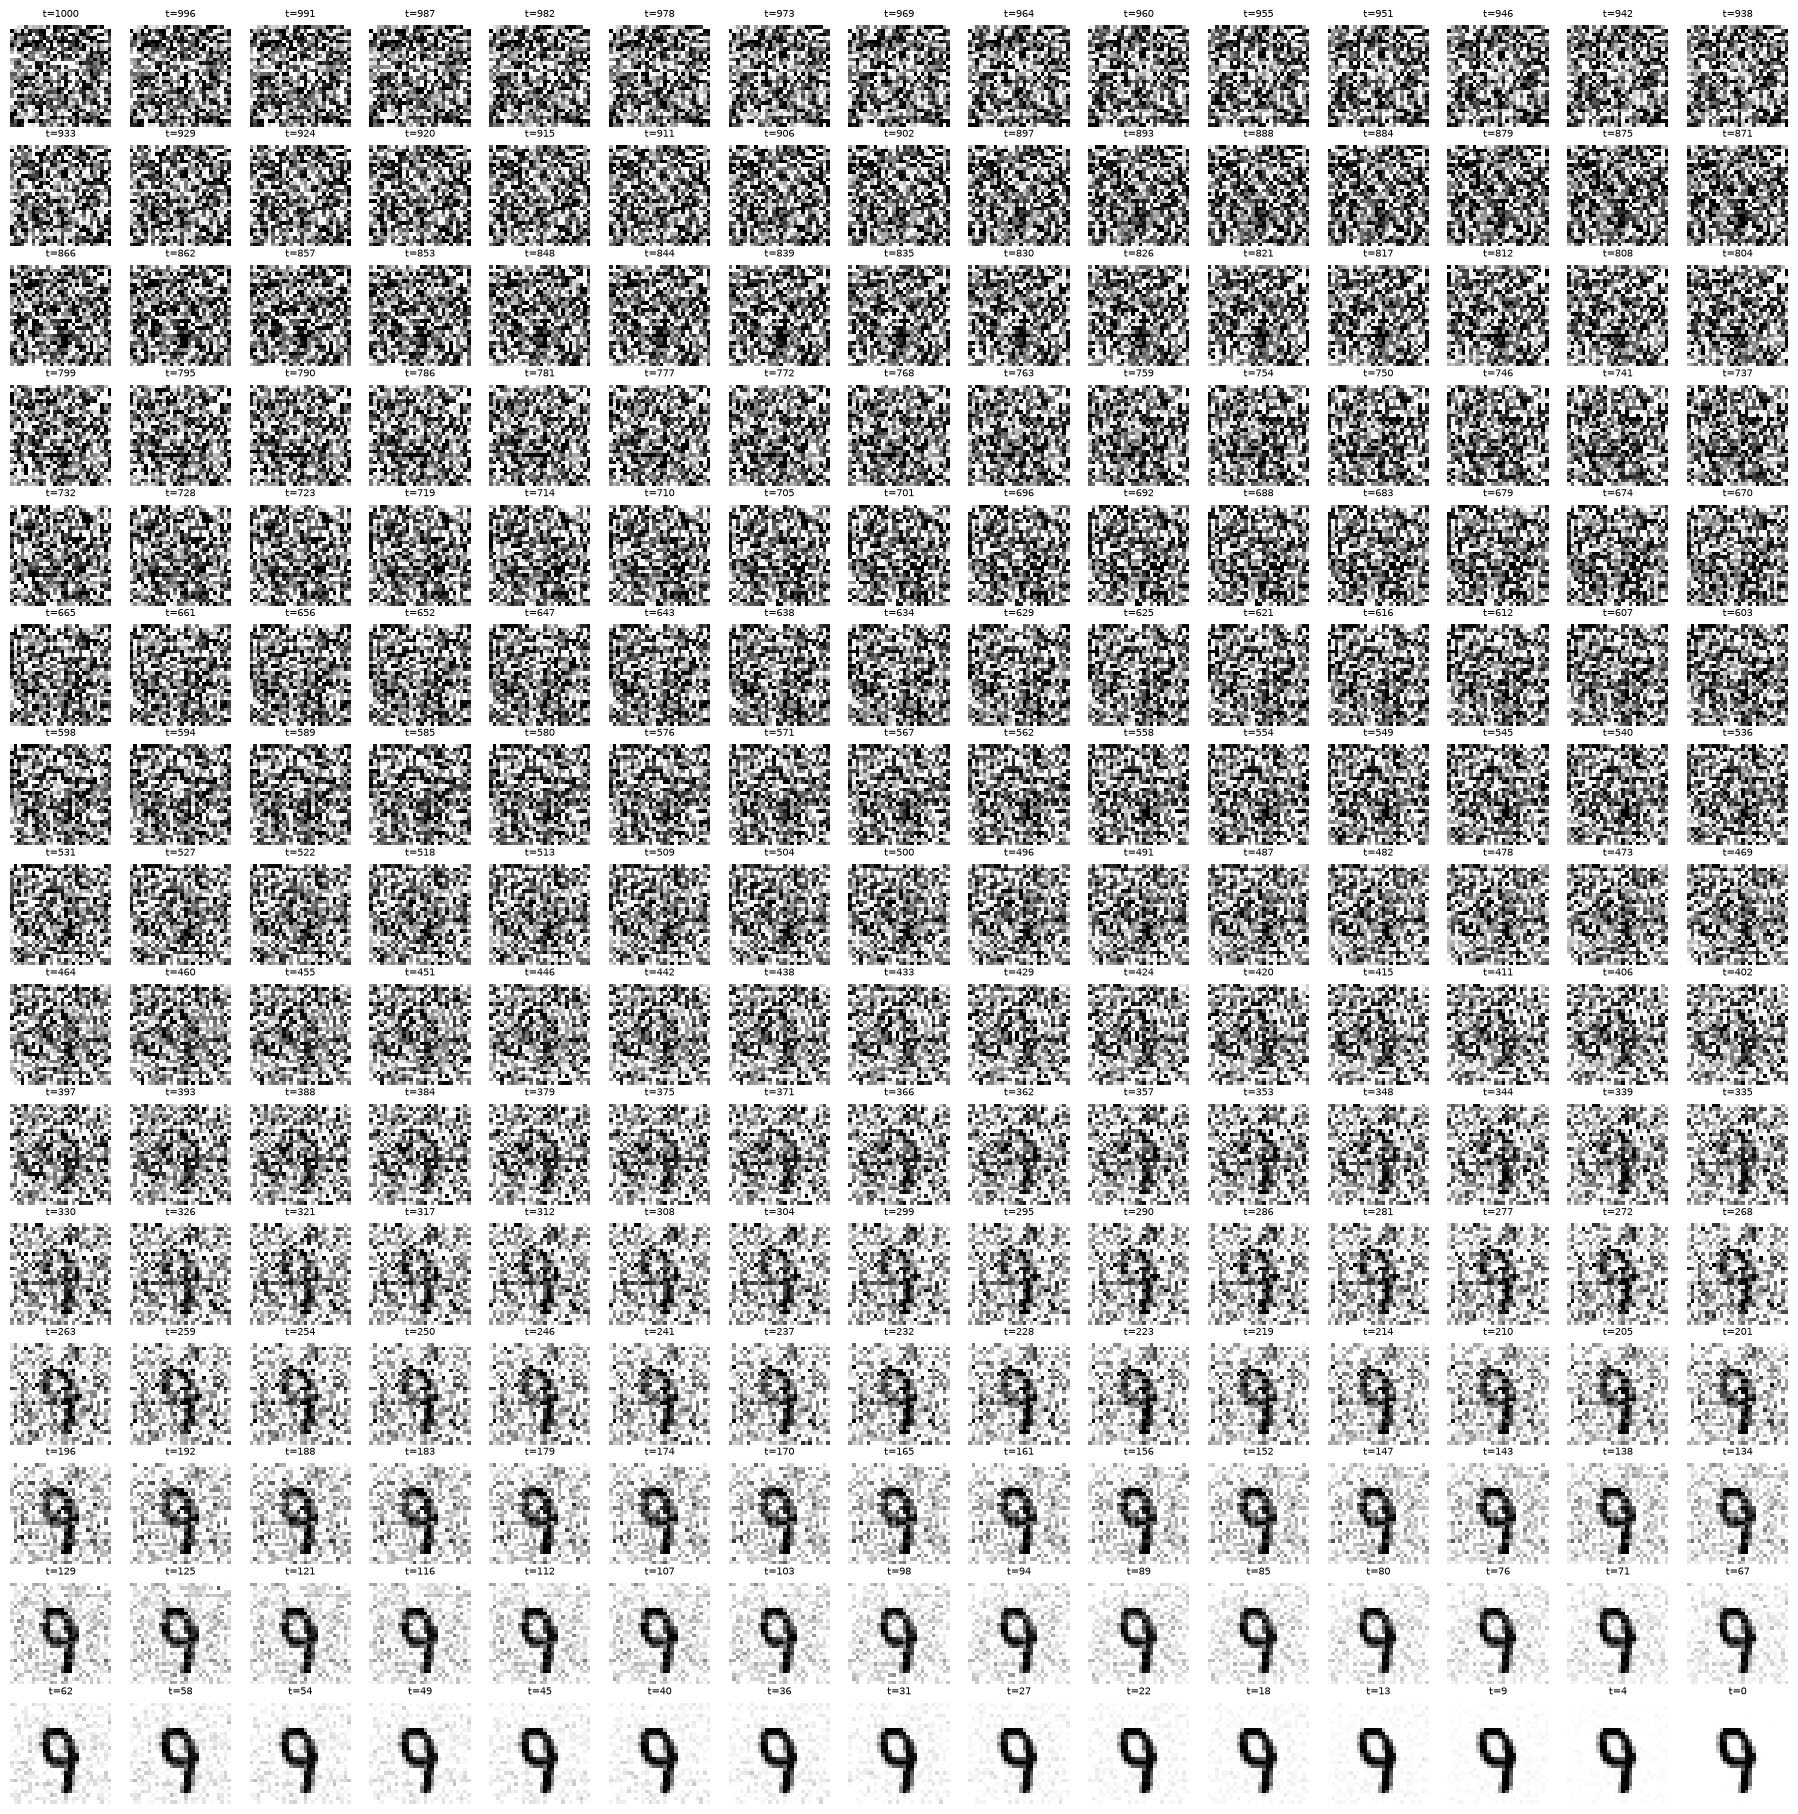

In [662]:
ddpm_model = result_ddpm["model"]
ddpm_model.eval()

nrows = 15
ncols = 15
number_of_frames = nrows * ncols

save_after = torch.linspace(
    0, ddpm_model.num_steps, steps=number_of_frames
).round().long().tolist()

save_after = set(save_after)

images = torch.randn(1, *ddpm_model.image_shape, device=device)
snapshots = [(ddpm_model.num_steps, images[0].cpu())]

with torch.no_grad():
    for step in reversed(range(ddpm_model.num_steps)):
        timesteps = torch.full(
            size=(1,),
            fill_value=step,
            dtype=torch.long,
            device=device,
        )

        predicted_noise = ddpm_model(images, timesteps)

        alpha = ddpm_model.alpha[step]
        alpha_bar = ddpm_model.alpha_bars[step]
        beta = ddpm_model.betas[step]

        images = (
            images
            - beta / torch.sqrt(1 - alpha_bar) * predicted_noise
        ) / torch.sqrt(alpha)

        if step > 0:
            images = images + torch.sqrt(beta) * torch.randn_like(images)

        completed_steps = ddpm_model.num_steps - step

        if completed_steps in save_after:
            snapshots.append((step, images[0].cpu()))

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(18, 18),
)

for ax, (remaining_steps, image) in zip(axes.flat, snapshots):
    display_image = ((image + 1) / 2).clamp(0, 1)

    ax.imshow(
        display_image.squeeze(0),
        cmap="gray_r",
        vmin=0,
        vmax=1,
    )
    ax.set_title(f"t={remaining_steps}", fontsize=7)
    ax.axis("off")

fig.tight_layout(pad=0.2)
plt.show()

## Final Discussion

| Model | Main observation | Main limitation |
| --- | --- | --- |
| VAE | A structured latent space supports gradual changes between samples. | Images can be blurred and digit regions overlap. |
| Conditional VAE | Labels provide direct control over the generated class. | Some samples remain soft or ambiguous. |
| GAN | Adversarial training produces recognizable digits. | Training is unstable and some shapes repeat. |
| GAN with gradient reversal | A shared backward pass can train both networks. | Its generator objective differs from the standard training setup. |
| Conditional GAN | Labels control the class while the latent input changes appearance. | Distorted or incomplete strokes remain possible. |
| DDPM | Repeated denoising produces varied digit images. | Generation requires many network evaluations. |

The experiments demonstrate different ways to learn an image distribution. Labels make generation easier to control, while latent plots and sampling trajectories help explain how each model works.

Visual results should be considered together with training curves. The losses use different objectives and scales, so their values cannot be used to rank all models. 